## STEP 1 
**Text Extraction AND Data Cleaning**

In [2]:
import requests 
from bs4 import BeautifulSoup

url = "https://midocean.edu.km/guide/"

response = requests.get(url)

print(response.status_code)

200


In [4]:
!pip install requests beautifulsoup4
from urllib.parse import urljoin, urlparse
import time

In [5]:
url = "https://midocean.edu.km/guide/"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/139.0.0.0 Safari/537.36"
}

response = requests.get(url, headers=headers, timeout=30)

print("Status Code:", response.status_code)

Status Code: 200


In [14]:

#يستخرج روابط الأقسام فقط

from urllib.parse import urljoin, urlparse

guide_url = "https://midocean.edu.km/guide/"

response = requests.get(
    guide_url,
    headers=headers,
    timeout=30
)

soup = BeautifulSoup(response.text, "html.parser")

section_links = []

for link in soup.find_all("a", href=True):
    title = link.get_text(" ", strip=True)
    href = link.get("href")

    full_url = urljoin(guide_url, href)

    # الأقسام اللي نحتاجها
    if title in [
        "القبول والتسجيل",
        "المالية",
        "العامة",
        "الأنشطة الطلابية",
        "الجودة",
        "الدعم",
        "السياسات المؤسسية"
    ]:
        section_links.append({
            "title": title,
            "url": full_url
        })

# إزالة التكرار
unique_sections = {}

for section in section_links:
    unique_sections[section["url"]] = section

section_links = list(unique_sections.values())

print("Number of sections:", len(section_links))



Number of sections: 7


In [16]:
#يدخل إلى كل رابط ويستخرج محتوى الصفحة الفعلي
documents = []

#المرور على جميع الأقسام
for i, section in enumerate(section_links, start=1):
    
#استخراج عنوان القسم و رابطه
    title = section["title"]
    page_url = section["url"]
#عرض
    print(f"[{i}/{len(section_links)}] Extracting: {title}")
    
#الهدف: إذا حدث خطأ أثناء جلب إحدى الصفحات، يحاول البرنامج معالجة الخطأ والانتقال إلى الصفحة التالية بدلًا من توقف البرنامج بالكامل
    try:
        response = requests.get(
            page_url,
            headers=headers,
            timeout=30
        )
#يرسل طلب إلى رابط القسم و يجلب محتوى الصفحة
        print("Status:", response.status_code)

        soup = BeautifulSoup(response.text, "html.parser")

        # حذف العناصر غير المهمة
        for element in soup([
            "script",
            "style",
            "nav",
            "header",
            "footer",
            "noscript"
        ]):
            element.decompose()

        # استخراج النص
        text = soup.get_text(
            separator="\n",
            strip=True
        )

        # تنظيف الأسطر الفارغة
        lines = [
            line.strip()
            for line in text.splitlines()
            if line.strip()
        ]

        clean_text = "\n".join(lines)

        # حفظ الوثيقة
        documents.append({
            "document_id": f"DOC_{i:03d}",
            "title": title,
            "url": page_url,
            "language": "ar",
            "source_type": "webpage",
            "content": clean_text
        })

        print("Characters extracted:", len(clean_text))
        print("-" * 60)

        time.sleep(1)

    except Exception as e:
        print("ERROR:", e)
        print("-" * 60)

print("\nExtraction completed!")
print("Documents extracted:", len(documents))

[1/7] Extracting: القبول والتسجيل
Status: 200
Characters extracted: 18480
------------------------------------------------------------
[2/7] Extracting: المالية
Status: 200
Characters extracted: 3776
------------------------------------------------------------
[3/7] Extracting: العامة
Status: 200
Characters extracted: 10808
------------------------------------------------------------
[4/7] Extracting: الأنشطة الطلابية
Status: 200
Characters extracted: 1539
------------------------------------------------------------
[5/7] Extracting: الجودة
Status: 200
Characters extracted: 4670
------------------------------------------------------------
[6/7] Extracting: الدعم
Status: 200
Characters extracted: 5313
------------------------------------------------------------
[7/7] Extracting: السياسات المؤسسية
Status: 200
Characters extracted: 2450
------------------------------------------------------------

Extraction completed!
Documents extracted: 7


In [18]:
# تنظيف الـ Noise من documents

noise_phrases = [
    "تخطي إلى المحتوى",
    "Menu",
    "Search",
    "Close this search box."
]

for doc in documents:
    lines = doc["content"].splitlines()

    cleaned_lines = []

    for line in lines:
        line = line.strip()

        # حذف الأسطر الفارغة
        if not line:
            continue

        # حذف عناصر الـ navigation والواجهة
        if line in noise_phrases:
            continue

        cleaned_lines.append(line)

    # تحديث المحتوى بعد التنظيف
    doc["content"] = "\n".join(cleaned_lines)

print("Cleaning completed!")

Cleaning completed!


In [20]:
# حفظ البيانات بعد الاستخراج والتنظيف

output_file = "midocean_documents_cleaned.json"

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(documents, f, ensure_ascii=False, indent=2)

print(f"Saved successfully: {output_file}")
print(f"Number of documents: {len(documents)}")

Saved successfully: midocean_documents_cleaned.json
Number of documents: 7


## STEP 2 
**Normalization** 
**توحيد حروف اللغة العربية و المسافات** 

In [96]:
import re

def normalize_arabic_keep_lines(text):
    lines = text.splitlines()
    cleaned_lines = []

    for line in lines:
        line = line.strip()

        if not line:
            continue

        # توحيد أشكال الألف
        line = re.sub(r'[إأآٱ]', 'ا', line)

        # توحيد الألف المقصورة
        line = line.replace('ى', 'ي')

        # إزالة التشكيل
        line = re.sub(
            r'[\u0617-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]',
            '',
            line
        )

        # إزالة التطويل
        line = line.replace('ـ', '')

        # توحيد المسافات داخل السطر فقط
        line = re.sub(r'[ \t]+', ' ', line).strip()

        if line:
            cleaned_lines.append(line)

    return "\n".join(cleaned_lines)


# تطبيق النسخة الجديدة على جميع الوثائق
for doc in documents:
    doc["normalized_text"] = normalize_arabic_keep_lines(
        doc["content"]
    )
    # حفظ البيانات بعد Arabic Normalization

normalized_file = "midocean_documents_normalized.json"

with open(normalized_file, "w", encoding="utf-8") as f:
    json.dump(documents, f, ensure_ascii=False, indent=2)

print("Normalization with line preservation completed!")
print("Saved successfully:", normalized_file)
print("Number of documents:", len(documents))

Normalization with line preservation completed!
Saved successfully: midocean_documents_normalized.json
Number of documents: 7


In [98]:
# إزالة Footer من جميع الوثائق

footer_start = "Youtube Facebook Instagram Linkedin"

for doc in documents:
    text = doc["normalized_text"]

    # البحث عن بداية الـ footer
    if footer_start in text:
        text = text.split(footer_start)[0].strip()

    # تحديث النص المنظم بعد إزالة الـ footer
    doc["normalized_text"] = text

print("Footer cleaning completed!")

Footer cleaning completed!


STEP 3 Chunking

In [100]:
#  من اكتشاف العناوين

def is_heading(line):
    line = line.strip()

    if not line:
        return False

    # العناوين قصيرة نسبيًا
    if len(line) > 150:
        return False

    # استبعاد القوائم المرقمة
    if re.match(r'^\d+[\-.)]', line):
        return False

    # استبعاد الروابط
    if line.startswith("http"):
        return False

    # استبعاد Footer
    if "جميع الحقوق محفوظة" in line:
        return False

    # استبعاد الأسطر التي تنتهي بعلامات استمرار الجملة
    if line.endswith((":", "،", "؛", ",")):
        return False

    # أسئلة FAQ تعتبر عناوين
    if line.endswith("؟"):
        return True

    # عبارات تبدأ عادة كمحتوى وليس كعنوان
    sentence_starters = [
        "ويمكن",
        "كما يمكن",
        "كما يتم",
        "كما يحق",
        "ويتم",
        "ويحق",
        "وفي حال",
        "في حال",
        "وفي حالة",
        "في حالة",
        "علما",
        "حيث",
        "لذلك",
        "لذا",
        "اذا",
        "إذا",
        "من خلال",
        "وفقا",
        "حسب",
        "علي",
        "على",
        "ان",
        "إن",
        "وكلمة السر"
    ]

    for starter in sentence_starters:
        if line.startswith(starter + " "):
            return False

    # الكلمات القصيرة جدًا غالبًا ليست عناوين
    words = line.split()

    if len(words) <= 2:
        valid_short_headings = [
            "القبول والتسجيل",
            "المالية",
            "العامة",
            "الجودة",
            "نظام الدراسة",
            "لغة الدراسة",
            "مدة الدراسة",
            "تغيير التخصص",
            "التاجيل"
        ]

        if line not in valid_short_headings:
            return False

    # إذا لم توجد علامات ترقيم، نعتبره Heading
    punctuation = ".,:؛،!؟"

    if not any(char in line for char in punctuation):
        return True

    return False


# اختبار العناوين النهائية
doc = documents[0]

headings = [
    line.strip()
    for line in doc["normalized_text"].splitlines()
    if is_heading(line)
]

print("Number of detected headings:", len(headings))

print("\nDetected headings:\n")

for heading in headings:
    print("-", heading)

Number of detected headings: 40

Detected headings:

- الاسئلة الشائعة (القبول والتسجيل) - Midocean University 2026
- لغة الدراسة
- طريقة الدراسة والاختبار
- مدة الدراسة
- برامج البكالوريوس التي تقدمها الجامعة
- برامج الماجستير التي تقدمها الجامعة
- برامج الدكتوراه التي تقدمها الجامعة
- تاجيل الفصل او الانسحاب منه
- تغيير التخصص
- الاختبار الاسبوعي (الاختبار القصير)
- التقدم للاختبار التكميلي
- التقدم للاختبار البديل
- الحضور في الساعات المكتبية
- دورة البحث العلمي
- الحصول علي الشهادة
- شروط قبول الطالب المستجد في الجامعة لبرنامج البكالوريوس
- شروط قبول الطالب المستجد في الجامعة لبرنامج الماجستير
- شروط قبول الطالب المستجد في الجامعة لبرنامج الدكتوراه
- الية القبول في برامج الدكتوراه
- نظام الدراسة
- المواظبة والحرمان من الدراسة
- التغيب عن الاختبار النهائي
- الانسحاب من مقرر او من الفصل الدراسي
- التاجيل
- حذف مقرر دراسي
- تغيير التخصص
- ضوابط اعادة القيد للطلاب المنقطعين عن الدراسة بالجامعة
- ضوابط اعادة القيد للطلاب الذين توقفوا عن الدراسة لمدة تزيد عن اربعة (4) فصول دراسية
- الحال

In [102]:

# إعادة إنشاء الـ Chunks باستخدام Heading Detection النهائي
# بعد معرفه العناوين نقوم بانشاء التشنك على حسب العناوين
# Section-Based Chunking / Semantic Chunking
import json

MAX_CHUNK_LENGTH = 1200
OVERLAP = 150

all_chunks = []


def split_long_text(text, max_length=1200, overlap=150):
    """تقسيم النصوص الطويلة مع overlap بسيط."""

    if len(text) <= max_length:
        return [text.strip()]

    chunks = []
    start = 0

    while start < len(text):

        end = min(start + max_length, len(text))

        # محاولة إنهاء الـ chunk عند نهاية جملة
        if end < len(text):

            possible_end = max(
                text.rfind("؟", start, end),
                text.rfind(".", start, end),
                text.rfind("؛", start, end)
            )

            if possible_end > start + 300:
                end = possible_end + 1

        chunk = text[start:end].strip()

        if chunk:
            chunks.append(chunk)

        if end >= len(text):
            break

        # Overlap
        start = max(end - overlap, start + 1)

    return chunks


for doc in documents:

    lines = [
        line.strip()
        for line in doc["normalized_text"].splitlines()
        if line.strip()
    ]

    sections = []

    current_section = "عام"
    current_text = []

    for line in lines:

        if is_heading(line):

            # حفظ القسم السابق
            if current_text:
                sections.append({
                    "section": current_section,
                    "text": " ".join(current_text).strip()
                })

            current_section = line
            current_text = []

        else:
            current_text.append(line)

    # حفظ آخر قسم
    if current_text:
        sections.append({
            "section": current_section,
            "text": " ".join(current_text).strip()
        })


    # تحويل الأقسام إلى Chunks
    for section in sections:

        section_name = section["section"]
        section_text = section["text"]

        # استبعاد قسم كلمة السر
        if "كلمة السر" in section_name:
            continue

        # تجاهل الأقسام الفارغة
        if not section_text:
            continue

        # حذف Footer إن وجد
        if "جميع الحقوق محفوظة" in section_text:
            section_text = section_text.split(
                "جميع الحقوق محفوظة"
            )[0].strip()

        if not section_text:
            continue

        # إضافة العنوان إلى النص
        full_text = f"{section_name}: {section_text}"

        text_parts = split_long_text(
            full_text,
            max_length=MAX_CHUNK_LENGTH,
            overlap=OVERLAP
        )

        for part_number, chunk_text in enumerate(
            text_parts,
            start=1
        ):

            chunk_id = (
                f'{doc["document_id"]}_'
                f'CHUNK_{len(all_chunks) + 1:04d}'
            )

            all_chunks.append({
                "chunk_id": chunk_id,
                "document_id": doc["document_id"],
                "title": doc["title"],
                "section": section_name,
                "url": doc["url"],
                "language": doc["language"],
                "text": chunk_text
            })


# حفظ CHUNKS
chunks_file = "midocean_chunks_final.json"

with open(chunks_file, "w", encoding="utf-8") as f:
    json.dump(
        all_chunks,
        f,
        ensure_ascii=False,
        indent=2
    )


print("Final chunking completed!")
print("Total chunks:", len(all_chunks))
print("Chunks saved successfully!")


Final chunking completed!
Total chunks: 102
Chunks saved successfully!


In [104]:
#الفحص النهائي للـ Dataset
#فحص جودة البيانات النهائي
from collections import Counter

# 1. أطوال الـ chunks
chunk_lengths = [
    len(chunk["text"].strip())
    for chunk in all_chunks
]

# 2. Chunks قصيرة جدًا
short_chunks = [
    chunk for chunk in all_chunks
    if len(chunk["text"].strip()) < 50
]

# 3. Chunk IDs مكررة
chunk_ids = [chunk["chunk_id"] for chunk in all_chunks]

duplicate_ids = {
    chunk_id
    for chunk_id in chunk_ids
    if chunk_ids.count(chunk_id) > 1
}

# 4. النصوص المكررة
chunk_texts = [
    chunk["text"].strip()
    for chunk in all_chunks
]

duplicate_texts = {
    text
    for text in chunk_texts
    if chunk_texts.count(text) > 1
}

# 5. الحقول المطلوبة
required_fields = [
    "chunk_id",
    "document_id",
    "title",
    "section",
    "url",
    "language",
    "text"
]

missing_fields = []

for chunk in all_chunks:

    missing = [
        field
        for field in required_fields
        if field not in chunk or not chunk[field]
    ]

    if missing:
        missing_fields.append({
            "chunk_id": chunk.get("chunk_id"),
            "missing": missing
        })


# 6. البحث عن Website Noise
noise_terms = [
    "Youtube",
    "Facebook",
    "Instagram",
    "Linkedin",
    "تخطي إلى المحتوى",
    "Close this search box",
    "Menu",
    "جميع الحقوق محفوظة"
]

noise_chunks = []

for chunk in all_chunks:

    found_noise = [
        term
        for term in noise_terms
        if term.lower() in chunk["text"].lower()
    ]

    if found_noise:
        noise_chunks.append({
            "chunk_id": chunk["chunk_id"],
            "terms": found_noise
        })


# 7. توزيع الـ chunks على الوثائق
chunks_per_document = Counter(
    chunk["document_id"]
    for chunk in all_chunks
)


# النتائج
print("=" * 60)
print("FINAL DATASET QUALITY CHECK")
print("=" * 60)

print("\nTotal documents:", len(documents))
print("Total chunks:", len(all_chunks))

print("\nChunks per document:")

for document_id, count in chunks_per_document.items():
    print(f"{document_id}: {count}")

print("\nChunk length statistics:")
print("Minimum:", min(chunk_lengths))
print("Maximum:", max(chunk_lengths))
print("Average:", round(sum(chunk_lengths) / len(chunk_lengths), 2))

print("\nShort chunks (< 50 characters):", len(short_chunks))
print("Duplicate Chunk IDs:", len(duplicate_ids))
print("Duplicate Chunk Texts:", len(duplicate_texts))
print("Missing required fields:", len(missing_fields))
print("Chunks containing website noise:", len(noise_chunks))


# عرض الـ chunks القصيرة إذا وجدت
if short_chunks:

    print("\n" + "=" * 60)
    print("SHORT CHUNKS")
    print("=" * 60)

    for chunk in short_chunks:
        print("-" * 50)
        print("Chunk ID:", chunk["chunk_id"])
        print("Section:", chunk["section"])
        print("Text:", chunk["text"])

FINAL DATASET QUALITY CHECK

Total documents: 7
Total chunks: 102

Chunks per document:
DOC_001: 37
DOC_002: 10
DOC_003: 19
DOC_004: 7
DOC_005: 7
DOC_006: 19
DOC_007: 3

Chunk length statistics:
Minimum: 27
Maximum: 1175
Average: 444.29

Short chunks (< 50 characters): 1
Duplicate Chunk IDs: 0
Duplicate Chunk Texts: 4
Missing required fields: 0
Chunks containing website noise: 7

SHORT CHUNKS
--------------------------------------------------
Chunk ID: DOC_002_CHUNK_0041
Section: يرجي الانتباه الي ما يلي
Text: يرجي الانتباه الي ما يلي: :


In [106]:
# فحص Chunks التي تحتوي على Website Noise

for item in noise_chunks:

    # البحث عن الـ chunk الأصلي داخل all_chunks
    matching_chunk = next(
        c for c in all_chunks
        if c["chunk_id"] == item["chunk_id"]
    )

    print("=" * 80)
    print("Chunk ID:", matching_chunk["chunk_id"])
    print("Document:", matching_chunk["document_id"])
    print("Section:", matching_chunk["section"])
    print("Detected noise:", item["terms"])
    print("Text:")
    print(matching_chunk["text"])
    print()

Chunk ID: DOC_001_CHUNK_0036
Document: DOC_001
Section: التحقق من السجلات الاكاديمية
Detected noise: ['Youtube', 'Facebook', 'Instagram', 'Linkedin']
Text:
التحقق من السجلات الاكاديمية: يحق للجامعة التحقق من صحة السجلات الاكاديمية والوثائق المقدمة من المؤسسة التعليمية السابقة. وفي حال ثبوت تقديم معلومات او وثائق غير صحيحة او مزورة، يحق للجامعة اتخاذ جميع الاجراءات النظامية المناسبة، بما في ذلك الفصل النهائي من الجامعة، والابلاغ عن المخالفة الي الجهات المختصة، وعدم رد الرسوم المدفوعة او اصدار اي سجلات اكاديمية، حتي وان تم اكتشاف المخالفة بعد تخرج الطالب. كما يحق للجامعة سحب الدرجة العلمية الممنوحة اذا ثبت ان الحصول عليها استند الي معلومات او وثائق غير صحيحة. Youtube Facebook Instagram Linkedin من نحن التقويم الاكاديمي الوظائف تواصل معنا الدليل والسياسات

Chunk ID: DOC_002_CHUNK_0046
Document: DOC_002
Section: يمكنك التعرف علي جميع تفاصيل سياسات استرداد الرسوم من خلال الرابط التالي >
Detected noise: ['Youtube', 'Facebook', 'Instagram', 'Linkedin']
Text:
يمكنك التعرف علي جميع تفاصيل سياسا

In [108]:
#  إزالة Website Footer Noise من جميع Chunks

footer_start = "Youtube"

for chunk in all_chunks:
    if footer_start in chunk["text"]:
        chunk["text"] = chunk["text"].split(footer_start)[0].strip()

print("Footer noise removed successfully")

Footer noise removed successfully


In [110]:
#  فحص الـChunks القصيرة بعد تنظيف الـFooter

short_chunks = [
    chunk for chunk in all_chunks
    if len(chunk["text"].strip()) < 50
]

print("Short chunks (< 50 characters):", len(short_chunks))
print()

for chunk in short_chunks:
    print("=" * 80)
    print("Chunk ID:", chunk["chunk_id"])
    print("Document:", chunk["document_id"])
    print("Section:", chunk["section"])
    print("Text:")
    print(repr(chunk["text"]))
    print()

Short chunks (< 50 characters): 1

Chunk ID: DOC_002_CHUNK_0041
Document: DOC_002
Section: يرجي الانتباه الي ما يلي
Text:
'يرجي الانتباه الي ما يلي: :'



In [112]:
#  حذف الـChunk غير المفيد

before_count = len(all_chunks)

all_chunks = [
    chunk
    for chunk in all_chunks
    if chunk["chunk_id"] != "DOC_002_CHUNK_0041"
]

after_count = len(all_chunks)

print("Chunks before:", before_count)
print("Chunks after:", after_count)
print("Removed:", before_count - after_count)

Chunks before: 102
Chunks after: 101
Removed: 1


In [116]:
#  Final Quality Check

from collections import Counter

print("=" * 80)
print("FINAL DATASET QUALITY CHECK")
print("=" * 80)

#  عدد الـchunks
print("Total chunks:", len(all_chunks))

# توزيع الـchunks حسب الوثيقة
chunks_per_document = Counter(
    chunk["document_id"]
    for chunk in all_chunks
)

print("\nChunks per document:")
for doc_id, count in sorted(chunks_per_document.items()):
    print(f"{doc_id}: {count}")

# أطوال الـchunks
chunk_lengths = [
    len(chunk["text"].strip())
    for chunk in all_chunks
]

print("\nChunk length statistics:")
print("Minimum:", min(chunk_lengths))
print("Maximum:", max(chunk_lengths))
print("Average:", round(sum(chunk_lengths) / len(chunk_lengths), 2))

# Chunks قصيرة جدًا
short_chunks = [
    chunk
    for chunk in all_chunks
    if len(chunk["text"].strip()) < 50
]

print("\nShort chunks (< 50 characters):", len(short_chunks))

# IDs مكررة
chunk_ids = [
    chunk["chunk_id"]
    for chunk in all_chunks
]

duplicate_ids = {
    chunk_id
    for chunk_id in chunk_ids
    if chunk_ids.count(chunk_id) > 1
}

print("Duplicate Chunk IDs:", len(duplicate_ids))

# نصوص مكررة
chunk_texts = [
    chunk["text"].strip()
    for chunk in all_chunks
]

duplicate_texts = {
    text
    for text in chunk_texts
    if chunk_texts.count(text) > 1
}

print("Duplicate Chunk Texts:", len(duplicate_texts))

# الحقول المطلوبة
required_fields = [
    "chunk_id",
    "document_id",
    "title",
    "section",
    "url",
    "language",
    "text"
]

missing_fields = []

for chunk in all_chunks:
    missing = [
        field
        for field in required_fields
        if field not in chunk or not chunk[field]
    ]

    if missing:
        missing_fields.append({
            "chunk_id": chunk.get("chunk_id"),
            "missing": missing
        })

print("Missing required fields:", len(missing_fields))

# Website Noise
noise_terms = [
    "Youtube",
    "Facebook",
    "Instagram",
    "Linkedin",
    "تخطي إلى المحتوى",
    "Close this search box",
    "Menu",
    "جميع الحقوق محفوظة"
]

noise_chunks = []

for chunk in all_chunks:
    found_noise = [
        term
        for term in noise_terms
        if term.lower() in chunk["text"].lower()
    ]

    if found_noise:
        noise_chunks.append({
            "chunk_id": chunk["chunk_id"],
            "terms": found_noise
        })

print("Chunks containing website noise:", len(noise_chunks))

print("\n" + "=" * 80)
print("FINAL CHECK COMPLETED")
print("=" * 80)

FINAL DATASET QUALITY CHECK
Total chunks: 101

Chunks per document:
DOC_001: 37
DOC_002: 9
DOC_003: 19
DOC_004: 7
DOC_005: 7
DOC_006: 19
DOC_007: 3

Chunk length statistics:
Minimum: 66
Maximum: 1175
Average: 441.7

Short chunks (< 50 characters): 0
Duplicate Chunk IDs: 0
Duplicate Chunk Texts: 4
Missing required fields: 0
Chunks containing website noise: 0

FINAL CHECK COMPLETED


In [118]:
#  حفظ الـFinal Dataset


output_file = "midocean_chunks_final.json"

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(
        all_chunks,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Final dataset saved successfully!")
print("File:", output_file)
print("Total chunks:", len(all_chunks))

Final dataset saved successfully!
File: midocean_chunks_final.json
Total chunks: 101


In [120]:
#  تحميل الـFinal Dataset
with open("midocean_chunks_final.json", "r", encoding="utf-8") as f:
    chunks = json.load(f)

print("Dataset loaded successfully!")
print("Total chunks:", len(chunks))
print("\nFirst chunk:")
print(chunks[0])

Dataset loaded successfully!
Total chunks: 101

First chunk:
{'chunk_id': 'DOC_001_CHUNK_0001', 'document_id': 'DOC_001', 'title': 'القبول والتسجيل', 'section': 'لغة الدراسة', 'url': 'https://midocean.edu.km/%d8%a7%d9%84%d8%a3%d8%b3%d8%a6%d9%84%d8%a9-%d8%a7%d9%84%d8%b4%d8%a7%d8%a6%d8%b9%d8%a9-%d8%a7%d9%84%d9%82%d8%a8%d9%88%d9%84-%d9%88%d8%a7%d9%84%d8%aa%d8%b3%d8%ac%d9%8a%d9%84/', 'language': 'ar', 'text': 'لغة الدراسة: برامج تدرس باللغة العربية مع المحتوي باللغة الانجليزية: 1- بكالوريوس الادارة. 2- بكالوريوس ادارة المشاريع. 3- بكالوريوس تقنية المعلومات. 4- ماجستير ادارة الاعمال. 5- ماجستير ادارة المخاطر. 6- ماجستير ادارة المشاريع. 7- ماجستير الادارة الصحية. 8- ماجستير الامن السيبراني. 9- ماجستير الاعلام الرقمي. 10- ماجستير التسويق الرقمي. 11- ماجستير ريادة الاعمال. 12- ماجستير الذكاء الاصطناعي. 13- ماجستير ادارة الموارد البشرية. 14- ماجستير التقنية المالية. 15- دكتوراه تقنية المعلومات. برامج تدرس باللغة العربية: 1- بكالوريوس التسويق الرقمي. 2- بكالوريوس الاعلام الرقمي. 3- بكالوريوس الر

## RQ1 - STEP 4 - Retrieval experiments
**A- FIRST  (SPARCE - BM25) RETRIEVAL MODEL**

**B- SECOND  (DENSE - BGE-M3) RETRIEVAL MODEL**

**C- THIRD  (Hybrid - RRF) RETRIEVAL MODEL**

## ----------------------------------------------

**FIRST (SPARCE - BM25) RETRIEVAL MODEL**

In [143]:
#  تثبيت مكتبة BM25
!pip install rank-bm25

In [147]:
#تجهيز النصوص للـBM25
#تجزئة النصوص: تقسيم النصوص بعد تطبيعها إلى كلمات منفصلة،
#مع إزالة علامات الترقيم والرموز وتوحيد المسافات، لتجهيزها لبناء فهرس الاسترجاع ومطابقة الأسئلة مع المقاطع النصية.
import re

def tokenize_arabic(text):
    # إزالة علامات الترقيم والرموز
    text = re.sub(r'[^\w\s]', ' ', text, flags=re.UNICODE)
    
    # توحيد المسافات
    text = re.sub(r'\s+', ' ', text).strip()
    
    # تقسيم النص إلى كلمات
    return text.split()


# إنشاء corpus من الـ101 chunks
corpus = [
    tokenize_arabic(chunk["text"])
    for chunk in chunks
]

print("BM25 corpus prepared successfully!")
print("Number of documents:", len(corpus))

print("\nExample tokenized chunk:")
print(corpus[0][:30])

BM25 corpus prepared successfully!
Number of documents: 101

Example tokenized chunk:
['لغة', 'الدراسة', 'برامج', 'تدرس', 'باللغة', 'العربية', 'مع', 'المحتوي', 'باللغة', 'الانجليزية', '1', 'بكالوريوس', 'الادارة', '2', 'بكالوريوس', 'ادارة', 'المشاريع', '3', 'بكالوريوس', 'تقنية', 'المعلومات', '4', 'ماجستير', 'ادارة', 'الاعمال', '5', 'ماجستير', 'ادارة', 'المخاطر', '6']


In [149]:
# بناء BM25 Index

from rank_bm25 import BM25Okapi

# بناء BM25 index
bm25 = BM25Okapi(corpus)

print("BM25 index built successfully!")
print("Number of indexed chunks:", len(bm25.doc_freqs))

BM25 index built successfully!
Number of indexed chunks: 101


In [154]:
#  BM25 Search Function

def bm25_search(query, top_k=5):
    
    # تجهيز الاستعلام
    query_tokens = tokenize_arabic(query)
    
    # حساب الدرجات
    scores = bm25.get_scores(query_tokens)
    
    # الحصول على أعلى النتائج
    top_indices = scores.argsort()[::-1][:top_k]
    
    results = []
    
    for rank, idx in enumerate(top_indices, start=1):
        
        chunk = chunks[idx]
        
        results.append({
            "rank": rank,
            "chunk_id": chunk["chunk_id"],
            "document_id": chunk["document_id"],
            "section": chunk["section"],
            "score": float(scores[idx]),
            "text": chunk["text"]
        })
    
    return results

In [158]:
evaluation_queries_final = [
    # =========================
    # القبول والتسجيل
    # =========================

    {
        "query_id": "Q01",
        "query": "ما هي البرامج المتاحة في مرحلة الماجستير؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0005"]
    },
    {
        "query_id": "Q02",
        "query": "هل تقدم الجامعة برامج للبكالوريوس؟ وما هي؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0004"]
    },
    {
        "query_id": "Q03",
        "query": "هل توجد برامج دكتوراه في الجامعة؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0006"]
    },
    {
        "query_id": "Q04",
        "query": "بأي لغة يتم تقديم المقررات الدراسية؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0001"]
    },
    {
        "query_id": "Q05",
        "query": "كم تستغرق الدراسة في الجامعة؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0003"]
    },
    {
        "query_id": "Q06",
        "query": "هل يستطيع الطالب تأجيل الفصل الدراسي؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0023"]
    },
    {
        "query_id": "Q07",
        "query": "ماذا يفعل الطالب إذا أراد تغيير تخصصه؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0008"]
    },
    {
        "query_id": "Q08",
        "query": "ما المقصود بالاختبار الأسبوعي القصير؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0009"]
    },
    {
        "query_id": "Q09",
        "query": "متى يمكن للطالب التقدم للاختبار التكميلي؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0010"]
    },
    {
        "query_id": "Q10",
        "query": "كيف يحصل الطالب على الشهادة بعد إكمال دراسته؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0014"]
    },

    # =========================
    # القبول والتسجيل - أسئلة مختلفة
    # =========================

    {
        "query_id": "Q11",
        "query": "ما شروط قبول الطالب الجديد في برنامج البكالوريوس؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0015"]
    },
    {
        "query_id": "Q12",
        "query": "ما متطلبات الالتحاق ببرنامج الماجستير؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0016"]
    },
    {
        "query_id": "Q13",
        "query": "ما شروط القبول في برامج الدكتوراه؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0017"]
    },
    {
        "query_id": "Q14",
        "query": "كيف تتم عملية القبول في برامج الدكتوراه؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0018"]
    },
    {
        "query_id": "Q15",
        "query": "ماذا يحدث عند التغيب عن الاختبار النهائي؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0021"]
    },
    {
        "query_id": "Q16",
        "query": "هل يمكن حذف مقرر دراسي بعد التسجيل فيه؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0024"]
    },
    {
        "query_id": "Q17",
        "query": "ما شروط إعادة قيد الطالب الذي توقف عن الدراسة لأربعة فصول دراسية أو أقل؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0026"]
    },
    {
        "query_id": "Q18",
        "query": "ما الإجراءات المطلوبة لإعادة قيد الطالب الذي توقف عن الدراسة لأكثر من أربعة فصول دراسية؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0027"]
    },
    {
        "query_id": "Q19",
        "query": "كيف يمكن للطالب التواصل مع الجامعة؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0030"]
    },
    {
        "query_id": "Q20",
        "query": "ما المتطلبات اللازمة لطلب معادلة المقررات؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0031"]
    },

    # =========================
    # المعادلات والرسوم
    # =========================

    {
        "query_id": "Q21",
        "query": "ما الشروط المطلوبة لمعادلة المقررات؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0032"]
    },
    {
        "query_id": "Q22",
        "query": "كم تبلغ رسوم معادلة المقرر الواحد؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0033"]
    },
    {
        "query_id": "Q23",
        "query": "هل يمكن تقسيط رسوم معادلة المقررات؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0033"]
    },
    {
        "query_id": "Q24",
        "query": "هل تؤثر معادلة المقرر على المعدل التراكمي؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0034"]
    },
    {
        "query_id": "Q25",
        "query": "كيف يتم التحقق من السجلات الأكاديمية؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0036"]
    },

    # =========================
    # المالية
    # =========================

    {
        "query_id": "Q26",
        "query": "ما الخطوات المطلوبة لسداد الرسوم؟",
        "relevant_chunk_ids": ["DOC_002_CHUNK_0038"]
    },
    {
        "query_id": "Q27",
        "query": "كيف يمكن للطالب دفع الرسوم الدراسية إلكترونيًا؟",
        "relevant_chunk_ids": ["DOC_002_CHUNK_0038"]
    },
    {
        "query_id": "Q28",
        "query": "ما العملة المستخدمة في سداد الرسوم؟",
        "relevant_chunk_ids": ["DOC_002_CHUNK_0043"]
    },
    {
        "query_id": "Q29",
        "query": "هل يمكن الدفع باستخدام بطاقة بنكية؟",
        "relevant_chunk_ids": ["DOC_002_CHUNK_0038"]
    },
    {
        "query_id": "Q30",
        "query": "ماذا يفعل الطالب إذا واجه مشكلة أثناء سداد الرسوم؟",
        "relevant_chunk_ids": ["DOC_002_CHUNK_0038"]
    },

    # =========================
    # العامة
    # =========================

    {
        "query_id": "Q31",
        "query": "كم تبلغ مدة الفصل الدراسي في برامج البكالوريوس والماجستير؟",
        "relevant_chunk_ids": ["DOC_003_CHUNK_0060"]
    },
    {
        "query_id": "Q32",
        "query": "من هي الجهة المانحة للشهادة العلمية للطالب؟",
        "relevant_chunk_ids": ["DOC_003_CHUNK_0058"]
    },
    {
        "query_id": "Q33",
        "query": "ما لغة المناهج وشرح المقررات الدراسية في الجامعة؟",
        "relevant_chunk_ids": ["DOC_003_CHUNK_0061"]
    },
    {
        "query_id": "Q34",
        "query": "ما الإجراءات المتعلقة بالانسحاب من مقرر أو من الفصل الدراسي؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0022"]
    },
    {
        "query_id": "Q35",
        "query": "ماذا يحدث عند الانسحاب من الفصل الدراسي؟",
        "relevant_chunk_ids": ["DOC_001_CHUNK_0022"]
    },

    # =========================
    # الأنشطة الطلابية
    # =========================

    {
        "query_id": "Q36",
        "query": "كيف يحصل الطالب على شهادة حضور دورة؟",
        "relevant_chunk_ids": ["DOC_004_CHUNK_0072"]
    },
    {
        "query_id": "Q37",
        "query": "هل يحصل الطالب على شهادة عند حضور ورشة عمل؟",
        "relevant_chunk_ids": ["DOC_004_CHUNK_0072"]
    },
    {
        "query_id": "Q38",
        "query": "كيف يمكن الحصول على شهادة الندوة أو الدورة؟",
        "relevant_chunk_ids": ["DOC_004_CHUNK_0072"]
    },

    # =========================
    # الجودة
    # =========================

    {
        "query_id": "Q39",
        "query": "هل جامعة ميداوشن معتمدة؟",
        "relevant_chunk_ids": ["DOC_005_CHUNK_0074"]
    },
    {
        "query_id": "Q40",
        "query": "ما الجمعية التي انضمت إليها كلية المعلوماتية بجامعة ميداوشن؟",
        "relevant_chunk_ids": ["DOC_005_CHUNK_0076"]
    },
    {
        "query_id": "Q41",
        "query": "هل جامعة ميداوشن معتمدة في دول معينة؟",
        "relevant_chunk_ids": ["DOC_005_CHUNK_0079"]
    },

    # =========================
    # الدعم
    # =========================

    {
        "query_id": "Q42",
        "query": "ماذا يحدث إذا انقطع الإنترنت أثناء الاختبار؟",
        "relevant_chunk_ids": ["DOC_006_CHUNK_0098"]
    },
    {
        "query_id": "Q43",
        "query": "كيف يتصرف الطالب عند انقطاع الكهرباء أثناء الاختبار؟",
        "relevant_chunk_ids": ["DOC_006_CHUNK_0098"]
    },
    {
        "query_id": "Q44",
        "query": "ما الحل إذا فقد الطالب الاتصال أثناء أداء الاختبار؟",
        "relevant_chunk_ids": ["DOC_006_CHUNK_0098"]
    },
    {
        "query_id": "Q45",
        "query": "ما الإجراءات المتبعة عند حدوث مشكلة تقنية أثناء الاختبار؟",
        "relevant_chunk_ids": ["DOC_006_CHUNK_0098"]
    },

    # =========================
    # السياسات المؤسسية
    # =========================

    {
        "query_id": "Q46",
        "query": "ما القيم التي تقوم عليها السياسات المؤسسية لجامعة ميداوشن؟",
        "relevant_chunk_ids": ["DOC_007_CHUNK_0100"]
    },
    {
        "query_id": "Q47",
        "query": "ما أهداف السياسات المؤسسية لجامعة ميداوشن؟",
        "relevant_chunk_ids": ["DOC_007_CHUNK_0100"]
    },
    {
        "query_id": "Q48",
        "query": "ما أنواع الشهادات التي يمكن للطالب الحصول عليها عند المشاركة في الأنشطة الطلابية؟",
        "relevant_chunk_ids": ["DOC_004_CHUNK_0072"]
    },

    # =========================
    # أسئلة متنوعة
    # =========================

    {
        "query_id": "Q49",
        "query": "ما الإجراءات المطلوبة لتأجيل الفصل لتجنب سداد الرسوم؟",
        "relevant_chunk_ids": ["DOC_003_CHUNK_0064"]
    },
    {
        "query_id": "Q50",
        "query": "ما الإجراءات التي يمكن اتباعها إذا واجه الطالب مشكلة في الاختبار الإلكتروني؟",
        "relevant_chunk_ids": ["DOC_006_CHUNK_0098"]
    }
]

print("Final evaluation dataset created!")
print("Number of queries:", len(evaluation_queries_final))

Final evaluation dataset created!
Number of queries: 50


In [160]:
with open("evaluation_queries_final.json", "w", encoding="utf-8") as f:
    json.dump(
        evaluation_queries_final,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Evaluation dataset saved")
print("Number of queries:", len(evaluation_queries_final))

Evaluation dataset saved
Number of queries: 50


In [170]:
#METRICS تعريف ال 
import numpy as np

# 1. Calculate Recall@K
def calculate_recall_at_k(results, relevant_ids, k):

    retrieved_ids = [
        result["chunk_id"] for result in results[:k]
    ]

    relevant_retrieved = set(retrieved_ids) & relevant_ids

    if not relevant_ids:
        return 0.0

    return len(relevant_retrieved) / len(relevant_ids)


# 2. Calculate Mean Reciprocal Rank (MRR)
def calculate_mrr(results, relevant_ids):

    for rank, result in enumerate(results, start=1):

        if result["chunk_id"] in relevant_ids:
            return 1 / rank

    return 0.0


# 3. Calculate NDCG@K
def calculate_ndcg_at_k(results, relevant_ids, k):

    retrieved_ids = [
        result["chunk_id"] for result in results[:k]
    ]

    relevance_scores = [
        1 if chunk_id in relevant_ids else 0
        for chunk_id in retrieved_ids
    ]

    dcg = sum(
        relevance / np.log2(rank + 1)
        for rank, relevance in enumerate(relevance_scores, start=1)
    )

    ideal_relevance = [1] * min(len(relevant_ids), k)

    idcg = sum(
        relevance / np.log2(rank + 1)
        for rank, relevance in enumerate(ideal_relevance, start=1)
    )

    if idcg == 0:
        return 0.0

    return dcg / idcg


print("Evaluation functions defined successfully!")

Evaluation functions defined successfully!


In [172]:
import pandas as pd

final_results = []

for item in evaluation_queries_final:
    
    query_id = item["query_id"]
    query = item["query"]
    relevant_ids = set(item["relevant_chunk_ids"])
    
    # Retrieve top 10 results
    results = bm25_search(query, top_k=10)
    
    # Calculate metrics
    recall_5 = calculate_recall_at_k(results, relevant_ids, 5)
    recall_10 = calculate_recall_at_k(results, relevant_ids, 10)
    mrr = calculate_mrr(results, relevant_ids)
    ndcg_10 = calculate_ndcg_at_k(results, relevant_ids, 10)
    
    final_results.append({
        "query_id": query_id,
        "query": query,
        "recall@5": recall_5,
        "recall@10": recall_10,
        "MRR": mrr,
        "NDCG@10": ndcg_10
    })


# Convert to DataFrame
final_results_df = pd.DataFrame(final_results)

# Calculate overall averages
final_metrics = {
    "Recall@5": final_results_df["recall@5"].mean(),
    "Recall@10": final_results_df["recall@10"].mean(),
    "MRR": final_results_df["MRR"].mean(),
    "NDCG@10": final_results_df["NDCG@10"].mean()
}

print("===== BM25 Final Evaluation =====")

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

===== BM25 Final Evaluation =====
Recall@5: 0.8000
Recall@10: 0.8400
MRR: 0.6455
NDCG@10: 0.6938


**B- SECOND  (DENSE - BGE-M3) RETRIEVAL MODEL**


In [174]:
!pip install -U sentence-transformers

In [180]:
#dense تحميل المودل  
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("BAAI/bge-m3")

print("BGE-M3 loaded successfully!")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

BGE-M3 loaded successfully!


In [182]:
print(type(model))

<class 'sentence_transformers.sentence_transformer.model.SentenceTransformer'>


In [184]:
# استخراج نصوص الـ chunks
chunk_texts = [chunk["text"] for chunk in chunks]

# إنشاء Dense Embeddings باستخدام BGE-M3
chunk_embeddings = model.encode(
    chunk_texts,
    batch_size=8,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Embeddings created successfully!")
print("Shape:", chunk_embeddings.shape)

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

Embeddings created successfully!
Shape: (101, 1024)


In [185]:
# استخراج نصوص الأسئلة
query_texts = [item["query"] for item in evaluation_queries_final]

# إنشاء Dense Embeddings للأسئلة
query_embeddings = model.encode(
    query_texts,
    batch_size=8,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Query embeddings created successfully!")
print("Shape:", query_embeddings.shape)

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Query embeddings created successfully!
Shape: (50, 1024)


In [186]:
import numpy as np

def dense_search(query_embedding, top_k=10):
    scores = np.dot(chunk_embeddings, query_embedding)
    top_indices = scores.argsort()[::-1][:top_k]

    results = []

    for rank, idx in enumerate(top_indices, start=1):
        chunk = chunks[idx]

        results.append({
            "rank": rank,
            "chunk_id": chunk["chunk_id"],
            "document_id": chunk["document_id"],
            "section": chunk["section"],
            "score": float(scores[idx]),
            "text": chunk["text"]
        })

    return results


# تشغيل Dense Retrieval على جميع الـ50 سؤال
dense_results = []

for i, item in enumerate(evaluation_queries_final):
    results = dense_search(
        query_embeddings[i],
        top_k=10
    )

    dense_results.append({
        "query_id": item["query_id"],
        "query": item["query"],
        "relevant_chunk_ids": item["relevant_chunk_ids"],
        "results": results
    })

print("Dense retrieval completed!")
print("Number of queries:", len(dense_results))

Dense retrieval completed!
Number of queries: 50


In [190]:
dense_evaluation = []

for item in dense_results:

    results = item["results"]
    relevant_ids = set(item["relevant_chunk_ids"])

    recall_5 = calculate_recall_at_k(
        results,
        relevant_ids,
        5
    )

    recall_10 = calculate_recall_at_k(
        results,
        relevant_ids,
        10
    )

    mrr = calculate_mrr(
        results,
        relevant_ids
    )

    ndcg_10 = calculate_ndcg_at_k(
        results,
        relevant_ids,
        10
    )

    dense_evaluation.append({
        "query_id": item["query_id"],
        "recall@5": recall_5,
        "recall@10": recall_10,
        "MRR": mrr,
        "NDCG@10": ndcg_10
    })

print("Dense evaluation completed!")

Dense evaluation completed!


In [192]:
dense_df = pd.DataFrame(dense_evaluation)
print("Dense Retrieval Results")
print("=" * 50)
print(f"Recall@5:  {dense_df['recall@5'].mean():.4f}")
print(f"Recall@10: {dense_df['recall@10'].mean():.4f}")
print(f"MRR:       {dense_df['MRR'].mean():.4f}")
print(f"NDCG@10:   {dense_df['NDCG@10'].mean():.4f}")

Dense Retrieval Results
Recall@5:  0.9400
Recall@10: 0.9600
MRR:       0.8258
NDCG@10:   0.8599


**C- THIRD  (Hybrid - RRF) RETRIEVAL MODEL**

In [198]:
# ==========================================
# Hybrid Retrieval: BM25 + BGE-M3
# Using Reciprocal Rank Fusion (RRF)
# ==========================================

def hybrid_search(query_embedding, query_text, top_k=10, rrf_k=60):
    
    # -------------------------
    # 1. BM25 ranking
    # -------------------------
    query_tokens = tokenize_arabic(query_text)
    bm25_scores = bm25.get_scores(query_tokens)
    
    bm25_indices = bm25_scores.argsort()[::-1]
    
    # -------------------------
    # 2. Dense ranking
    # -------------------------
    dense_scores = np.dot(chunk_embeddings, query_embedding)
    
    dense_indices = dense_scores.argsort()[::-1]
    
    # -------------------------
    # 3. RRF scores
    # -------------------------
    rrf_scores = np.zeros(len(chunks))
    
    for rank, idx in enumerate(bm25_indices, start=1):
        rrf_scores[idx] += 1 / (rrf_k + rank)
    
    for rank, idx in enumerate(dense_indices, start=1):
        rrf_scores[idx] += 1 / (rrf_k + rank)
    
    # -------------------------
    # 4. Get top-k
    # -------------------------
    top_indices = rrf_scores.argsort()[::-1][:top_k]
    
    results = []
    
    for rank, idx in enumerate(top_indices, start=1):
        chunk = chunks[idx]
        
        results.append({
            "rank": rank,
            "chunk_id": chunk["chunk_id"],
            "document_id": chunk["document_id"],
            "section": chunk["section"],
            "score": float(rrf_scores[idx]),
            "text": chunk["text"]
        })
    
    return results

print("Hybrid search function created successfully!")

Hybrid search function created successfully!


In [200]:
# ==========================================
# Run Hybrid Retrieval on all 50 queries
# ==========================================

hybrid_results = []

for i, item in enumerate(evaluation_queries_final):
    
    results = hybrid_search(
        query_embedding=query_embeddings[i],
        query_text=item["query"],
        top_k=10
    )
    
    hybrid_results.append({
        "query_id": item["query_id"],
        "query": item["query"],
        "relevant_chunk_ids": item["relevant_chunk_ids"],
        "results": results
    })

print("Hybrid retrieval completed!")
print("Number of queries:", len(hybrid_results))

Hybrid retrieval completed!
Number of queries: 50


In [204]:
# ==========================================
# Evaluate Hybrid Retrieval
# ==========================================

hybrid_evaluation = []

for item in hybrid_results:
    
    results = item["results"]
    relevant_ids = set(item["relevant_chunk_ids"])

    hybrid_evaluation.append({
        "query_id": item["query_id"],
        "recall@5": calculate_recall_at_k(
            results, relevant_ids, 5
        ),
        "recall@10": calculate_recall_at_k(
            results, relevant_ids, 10
        ),
        "MRR": calculate_mrr(
            results, relevant_ids
        ),
        "NDCG@10": calculate_ndcg_at_k(
            results, relevant_ids, 10
        )
    })

hybrid_df = pd.DataFrame(hybrid_evaluation)

print("Hybrid evaluation completed!")

Hybrid evaluation completed!


In [206]:
print("Hybrid BM25 + BGE-M3 Results")
print("=" * 50)

print(f"Recall@5  : {hybrid_df['recall@5'].mean():.4f}")
print(f"Recall@10 : {hybrid_df['recall@10'].mean():.4f}")
print(f"MRR       : {hybrid_df['MRR'].mean():.4f}")
print(f"NDCG@10   : {hybrid_df['NDCG@10'].mean():.4f}")

Hybrid BM25 + BGE-M3 Results
Recall@5  : 0.9400
Recall@10 : 0.9800
MRR       : 0.7758
NDCG@10   : 0.8257


## DISPLAY visualization

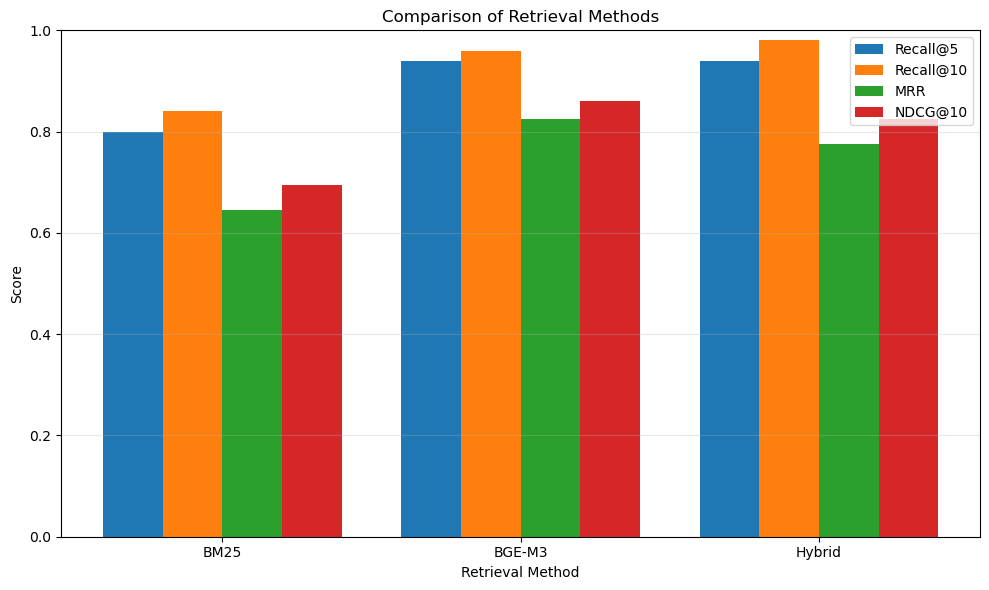

In [208]:
import matplotlib.pyplot as plt
import numpy as np

methods = ["BM25", "BGE-M3", "Hybrid"]

recall_5 = [0.80, 0.94, 0.94]
recall_10 = [0.84, 0.96, 0.98]
mrr = [0.6455, 0.8258, 0.7758]
ndcg_10 = [0.6938, 0.8599, 0.8257]

x = np.arange(len(methods))
width = 0.2

plt.figure(figsize=(10, 6))

plt.bar(x - 1.5*width, recall_5, width, label="Recall@5")
plt.bar(x - 0.5*width, recall_10, width, label="Recall@10")
plt.bar(x + 0.5*width, mrr, width, label="MRR")
plt.bar(x + 1.5*width, ndcg_10, width, label="NDCG@10")

plt.xlabel("Retrieval Method")
plt.ylabel("Score")
plt.title("Comparison of Retrieval Methods")
plt.xticks(x, methods)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

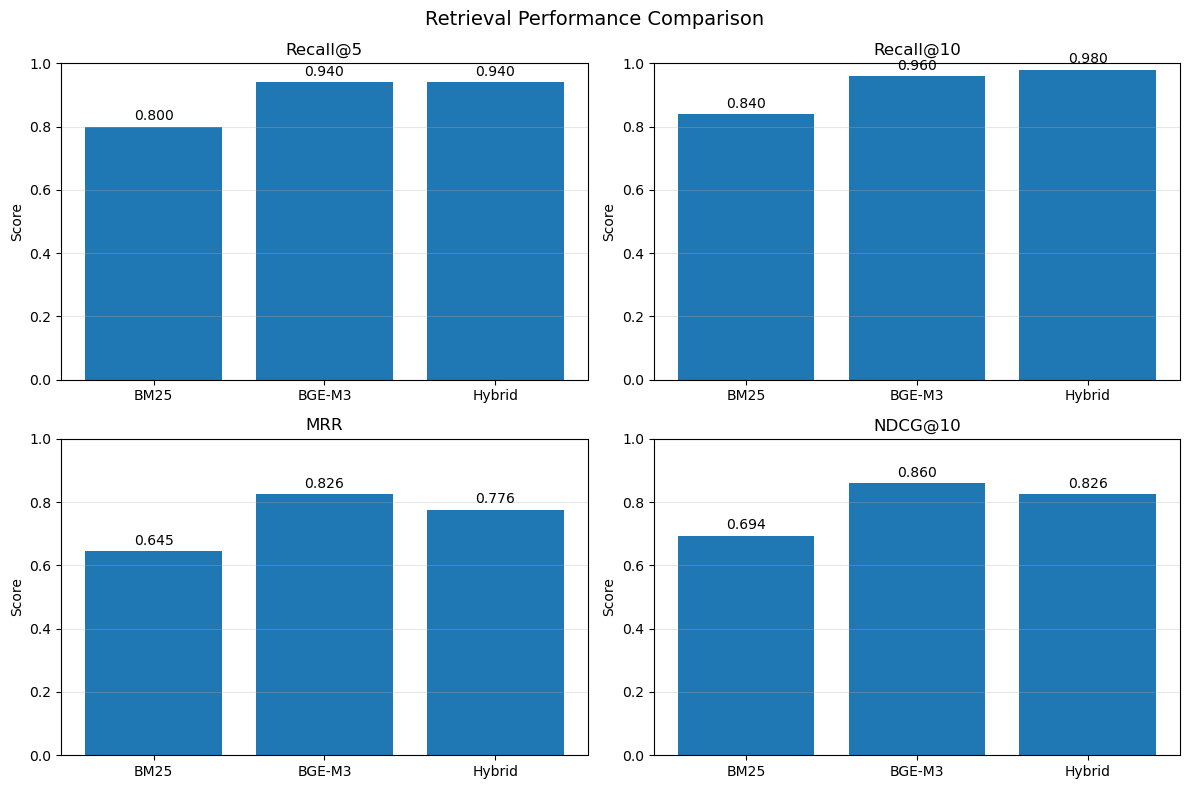

In [211]:
metrics = {
    "Recall@5": [0.80, 0.94, 0.94],
    "Recall@10": [0.84, 0.96, 0.98],
    "MRR": [0.6455, 0.8258, 0.7758],
    "NDCG@10": [0.6938, 0.8599, 0.8257]
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (metric, values) in zip(axes.flat, metrics.items()):
    bars = ax.bar(methods, values)
    
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.3)
    
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.02,
            f"{value:.3f}",
            ha="center"
        )

plt.suptitle("Retrieval Performance Comparison", fontsize=14)
plt.tight_layout()
plt.show()

In [213]:
with open("hybrid_results.json", "w", encoding="utf-8") as f:
    json.dump(hybrid_results, f, ensure_ascii=False, indent=2)

print("Hybrid results saved successfully!")
print("Number of queries:", len(hybrid_results))

Hybrid results saved successfully!
Number of queries: 50


## RQ2 - STEP 5 - Hybrid + reranking


In [219]:
## RERANK تحميل مودل ال  
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

reranker_name = "BAAI/bge-reranker-v2-m3"

tokenizer = AutoTokenizer.from_pretrained(reranker_name)
reranker_model = AutoModelForSequenceClassification.from_pretrained(
    reranker_name
)

reranker_model.eval()

print("Reranker loaded successfully!")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Reranker loaded successfully!


In [220]:
print(type(reranker_model))
print(type(tokenizer))

<class 'transformers.models.xlm_roberta.modeling_xlm_roberta.XLMRobertaForSequenceClassification'>
<class 'transformers.models.xlm_roberta.tokenization_xlm_roberta.XLMRobertaTokenizer'>


In [103]:
def rerank_results(query, results):
    pairs = [
        [query, result["text"]]
        for result in results
    ]

    inputs = tokenizer(
        pairs,
        padding=True,
        truncation=True,
        return_tensors="pt"
    )

    with torch.no_grad():
        outputs = reranker_model(**inputs)

    scores = outputs.logits.view(-1).cpu().numpy()

    reranked = []

    for result, score in zip(results, scores):
        reranked.append({
            **result,
            "reranker_score": float(score)
        })

    reranked.sort(
        key=lambda x: x["reranker_score"],
        reverse=True
    )

    for rank, result in enumerate(reranked, start=1):
        result["rerank_rank"] = rank

    return reranked

In [104]:
reranked_all = []

for i, item in enumerate(evaluation_queries_final):

    query = item["query"]

    # Hybrid retrieves Top-20 candidates
    hybrid_results = hybrid_search(
        query_embedding=query_embeddings[i],
        query_text=query,
        top_k=20
    )

    # Rerank the Top-20
    reranked_results = rerank_results(
        query=query,
        results=hybrid_results
    )

    # Keep Top-10 after reranking
    top_10 = reranked_results[:10]

    reranked_all.append({
        "query_id": item["query_id"],
        "query": query,
        "relevant_chunk_ids": item["relevant_chunk_ids"],
        "results": top_10
    })

print("Reranking completed for", len(reranked_all), "queries.")

Reranking completed for 50 queries.


In [105]:
# Calculate metrics after reranking

recall_5_reranked = []
recall_10_reranked = []
mrr_reranked = []
ndcg_10_reranked = []

for item in reranked_all:
    results = item["results"]
    relevant_ids = item["relevant_chunk_ids"]

    recall_5_reranked.append(
        calculate_recall_at_k(results, relevant_ids, 5)
    )

    recall_10_reranked.append(
        calculate_recall_at_k(results, relevant_ids, 10)
    )

    mrr_reranked.append(
        calculate_mrr(results, relevant_ids)
    )

    ndcg_10_reranked.append(
        calculate_ndcg_at_k(results, relevant_ids, 10)
    )

print("RQ2 - Hybrid + Reranking")
print("-------------------------")
print(f"Recall@5:  {np.mean(recall_5_reranked):.4f}")
print(f"Recall@10: {np.mean(recall_10_reranked):.4f}")
print(f"MRR:       {np.mean(mrr_reranked):.4f}")
print(f"NDCG@10:   {np.mean(ndcg_10_reranked):.4f}")

RQ2 - Hybrid + Reranking
-------------------------
Recall@5:  0.9800
Recall@10: 0.9800
MRR:       0.8800
NDCG@10:   0.9057


In [106]:
# Final comparison table for RQ1 and RQ2

final_results = [
    {
        "Method": "BM25 (Sparse)",
        "Recall@5": 0.8000,
        "Recall@10": 0.8400,
        "MRR": 0.6455,
        "NDCG@10": 0.6938
    },
    {
        "Method": "BGE-M3 (Dense)",
        "Recall@5": 0.9400,
        "Recall@10": 0.9600,
        "MRR": 0.8258,
        "NDCG@10": 0.8599
    },
    {
        "Method": "Hybrid (BM25 + BGE-M3)",
        "Recall@5": 0.9400,
        "Recall@10": 0.9800,
        "MRR": 0.7758,
        "NDCG@10": 0.8257
    },
    {
        "Method": "Hybrid + Reranking",
        "Recall@5": 0.9800,
        "Recall@10": 0.9800,
        "MRR": 0.8800,
        "NDCG@10": 0.9057
    }
]

final_results_df = pd.DataFrame(final_results)

final_results_df

,Method,Recall@5,Recall@10,MRR,NDCG@10
0,BM25 (Sparse),0.80,0.84,0.6455,0.6938
1,BGE-M3 (Dense),0.94,0.96,0.8258,0.8599
2,Hybrid (BM25 + BGE-M3),0.94,0.98,0.7758,0.8257
3,Hybrid + Reranking,0.98,0.98,0.8800,0.9057


In [107]:
final_results_df.to_csv(
    "RQ1_RQ2_final_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved successfully!")

Saved successfully!


In [108]:
with open("reranked_all.json", "w", encoding="utf-8") as f:
    json.dump(reranked_all, f, ensure_ascii=False, indent=2)

print("Saved successfully!")

Saved successfully!
